# 1 · Mean-variance optimisation and Black-Litterman
A 12-stock, 6-sector universe (2012 to present). We build the efficient frontier, compare classic portfolios, then use **Black-Litterman** to blend market-implied returns with explicit investor views. This fixes the main weakness of Markowitz: its sensitivity to noisy return estimates.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
prices = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_prices.py
bench = prices.pop("SPY")
rets = np.log(prices).diff().dropna()
RF = 0.025  # average T-bill rate over the sample (approx.)
from portopt import covariance, optimize, black_litterman as bl

In [2]:
mu_hist = rets.mean() * 252
cov = covariance.ledoit_wolf(rets)
stats = pd.DataFrame({"ann. return": mu_hist, "ann. vol": np.sqrt(np.diag(cov)), "Sharpe": (mu_hist - RF) / np.sqrt(np.diag(cov))})
stats.sort_values("Sharpe", ascending=False).round(3)

,ann. return,ann. vol,Sharpe
NVDA,0.425,0.442,0.904
MSFT,0.217,0.265,0.726
AAPL,0.227,0.283,0.714
JPM,0.181,0.260,0.601
JNJ,0.126,0.176,0.574
GS,0.172,0.282,0.521
BAC,0.164,0.300,0.464
KO,0.099,0.174,0.427
PG,0.091,0.179,0.369
XOM,0.083,0.255,0.229


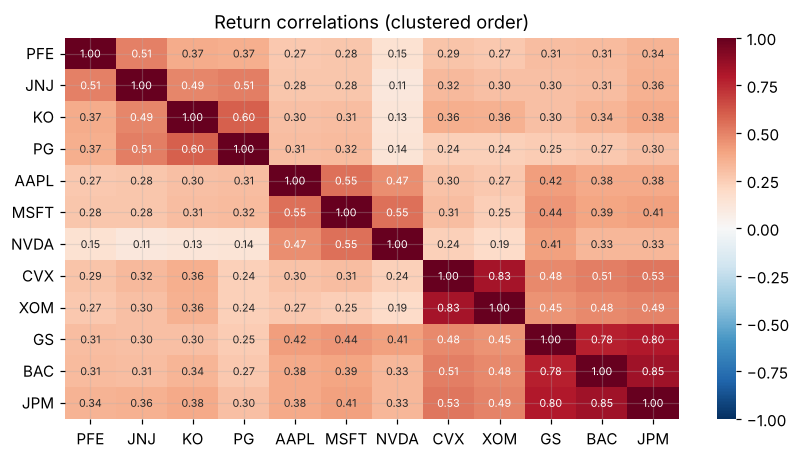

In [3]:
corr = rets.corr()
order = optimize.quasi_diag_order(corr)
sns.heatmap(corr.loc[order, order], cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Return correlations (clustered order)"); plt.show()

## Efficient frontier

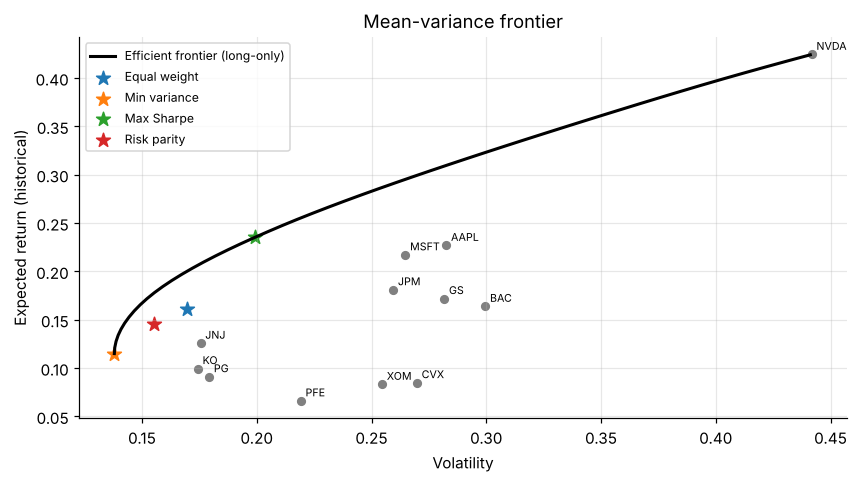

,Equal weight,Min variance,Max Sharpe,Risk parity
AAPL,0.083,0.022,0.131,0.072
BAC,0.083,0.000,0.000,0.059
CVX,0.083,0.000,0.000,0.071
GS,0.083,0.011,0.000,0.062
JNJ,0.083,0.251,0.386,0.120
JPM,0.083,0.000,0.093,0.065
KO,0.083,0.235,0.039,0.117
MSFT,0.083,0.054,0.061,0.075
NVDA,0.083,0.017,0.290,0.055
PFE,0.083,0.100,0.000,0.102


In [4]:
frontier = optimize.efficient_frontier(mu_hist, cov, 50)
ports = {"Equal weight": optimize.equal_weight(cov), "Min variance": optimize.min_variance(cov),
         "Max Sharpe": optimize.max_sharpe(mu_hist, cov, RF), "Risk parity": optimize.risk_parity(cov)}
plt.plot(frontier.vol, frontier.ret, "k-", lw=2, label="Efficient frontier (long-only)")
plt.scatter(np.sqrt(np.diag(cov)), mu_hist, c="grey", s=25)
for t in mu_hist.index: plt.annotate(t, (np.sqrt(cov.loc[t, t]), mu_hist[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
for name, w in ports.items():
    s = optimize.portfolio_stats(w, mu_hist, cov, RF); plt.scatter(s["volatility"], s["return"], s=90, marker="*", label=name)
plt.xlabel("Volatility"); plt.ylabel("Expected return (historical)"); plt.title("Mean-variance frontier"); plt.legend(fontsize=8)
plt.savefig(IMG / "efficient_frontier.png", bbox_inches="tight"); plt.show()
pd.DataFrame(ports).round(3)

Max-Sharpe on historical means puts most of the weight in a few past winners and gives zero weight to half the universe. That is the classic **estimation-error** problem: small changes in the estimated means move the weights a lot. Black-Litterman starts from the market equilibrium instead.

## Black-Litterman
Market-cap weights are approximated by price × fixed share counts (in billions, rounded), which is enough to set the equilibrium prior.

In [5]:
shares_bn = pd.Series({"AAPL": 14.8, "MSFT": 7.4, "NVDA": 24.4, "JPM": 2.8, "BAC": 7.6, "GS": 0.31,
                       "JNJ": 2.4, "PFE": 5.7, "XOM": 4.3, "CVX": 1.75, "PG": 2.35, "KO": 4.3})
mcap = prices.iloc[-1] * shares_bn
w_mkt = mcap / mcap.sum()
delta = bl.risk_aversion_from_market(np.log(bench).diff().dropna(), RF)
delta = float(np.clip(delta, 1.5, 4.0))
pi = bl.implied_returns(cov, w_mkt, delta, RF)
print(f"risk aversion delta = {delta:.2f}")

views = [("XOM", 0.18),                  # absolute: XOM returns 18% (equilibrium implies ~11%)
         (("JNJ", "PFE"), 0.03),          # relative: JNJ beats PFE by 3%
         (("MSFT", "AAPL"), 0.02)]        # relative: MSFT beats AAPL by 2%
P, Q = bl.make_views(cov.index, views)
mu_bl, cov_bl = bl.posterior(cov, pi, P, Q, tau=0.05, view_confidence=[0.6, 0.5, 0.4])
w_bl = optimize.max_sharpe(mu_bl, cov_bl, RF, max_weight=0.35)
comp = pd.DataFrame({"equilibrium return": pi, "BL return": mu_bl, "market weight": w_mkt,
                     "BL max-Sharpe weight": w_bl, "historical max-Sharpe": ports["Max Sharpe"]})
comp["tilt vs market"] = comp["BL max-Sharpe weight"] - comp["market weight"]
comp.round(3)

risk aversion delta = 4.00


,equilibrium return,BL return,market weight,BL max-Sharpe weight,historical max-Sharpe,tilt vs market
AAPL,0.232,0.233,0.297,0.200,0.131,-0.097
BAC,0.173,0.193,0.022,0.016,0.000,-0.006
CVX,0.132,0.166,0.021,0.016,0.000,-0.005
GS,0.178,0.196,0.016,0.012,0.000,-0.004
JNJ,0.078,0.092,0.038,0.099,0.386,0.061
JPM,0.157,0.175,0.054,0.039,0.093,-0.015
KO,0.081,0.091,0.024,0.010,0.039,-0.014
MSFT,0.216,0.231,0.217,0.223,0.061,0.006
NVDA,0.361,0.372,0.239,0.201,0.290,-0.038
PFE,0.091,0.084,0.009,0.000,0.000,-0.009


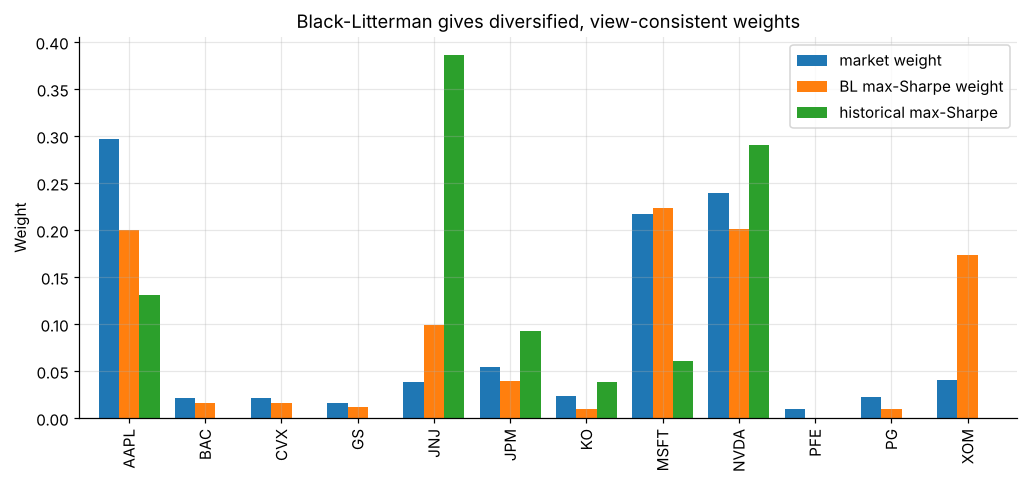

In [6]:
ax = comp[["market weight", "BL max-Sharpe weight", "historical max-Sharpe"]].plot.bar(figsize=(11, 4.5), width=0.8)
ax.set_title("Black-Litterman gives diversified, view-consistent weights"); ax.set_ylabel("Weight")
plt.savefig(IMG / "black_litterman_weights.png", bbox_inches="tight"); plt.show()

**Takeaway:** the BL portfolio stays anchored to market weights and moves mainly where we expressed views (see the *tilt vs market* column: XOM, JNJ vs PFE, MSFT vs AAPL). Assets without views keep weights close to the market. The historical optimiser, by contrast, bets on a few names.